## Configuration
Edit the cell below to change the input data or experiment name. Run it first in **every** kernel session (including after the kernel restart before Phase II). All outputs go to `outputs/<EXPERIMENT_NAME>/`.

In [ ]:
# ── Experiment configuration: the only cell to edit when changing input data ──
import json
from pathlib import Path

EXPERIMENT_NAME = "elline_peaks_10x"

# One BED file per class (chrom, start, end; extra columns are ignored).
INPUT_BEDS = {
    "positive": "./input_training_data/elline_positive_peaks.hg38.bed",
    "control":  "./input_training_data/elline_control_10x_1kb.bed",
}
CLASS_LABELS = {"positive": 1, "control": 0}   # binary target for each class above

SAMPLE_SIZE     = None       # intervals per class for Phase I; None = use all regions
RANDOM_SEED     = 42
SEQUENCE_LENGTH = 16384    # AlphaGenome input length: 16384, 131072, 524288 or 1048576
CHUNK_SIZE      = 200      # intervals per inference/HDF5 write chunk

# Phase II (CNN) settings
BATCH_SIZE = 64
EPOCHS     = 50
VAL_FRAC   = 0.1

# Outputs: outputs/<EXPERIMENT_NAME>/{phase_I_features, phase_II_model}
OUTPUT_ROOT   = Path("./outputs")
RUN_DIR       = OUTPUT_ROOT / EXPERIMENT_NAME
PHASE_I_DIR   = RUN_DIR / "phase_I_features"
PHASE_II_DIR  = RUN_DIR / "phase_II_model"
FEATURE_FILES = {label: PHASE_I_DIR / f"{label}_features.h5" for label in INPUT_BEDS}

if set(INPUT_BEDS) != set(CLASS_LABELS):
    raise ValueError("INPUT_BEDS and CLASS_LABELS must have the same keys")
if set(CLASS_LABELS.values()) != {0, 1}:
    raise ValueError("CLASS_LABELS must contain both 0 and 1")
for label, bed in INPUT_BEDS.items():
    if not Path(bed).exists():
        raise FileNotFoundError(f"[{label}] BED file not found: {bed}")

PHASE_I_DIR.mkdir(parents=True, exist_ok=True)
PHASE_II_DIR.mkdir(parents=True, exist_ok=True)

with open(RUN_DIR / "config.json", "w") as f:
    json.dump({
        "experiment_name": EXPERIMENT_NAME, "input_beds": INPUT_BEDS, "class_labels": CLASS_LABELS,
        "sample_size": SAMPLE_SIZE, "random_seed": RANDOM_SEED, "sequence_length": SEQUENCE_LENGTH,
        "batch_size": BATCH_SIZE, "epochs": EPOCHS, "val_frac": VAL_FRAC,
    }, f, indent=2)

print(f"Experiment : {EXPERIMENT_NAME}")
print(f"Outputs    : {RUN_DIR.resolve()}")

Experiment : elline_peaks_10x
Outputs    : /vf/users/Dcode/gaetano/projects/AlphaGenome_TREDNet/outputs/elline_peaks_10x


## Imports

In [2]:
import os

from alphagenome.data import genome
from alphagenome.visualization import plot_components
from alphagenome_research.model import dna_model
from alphagenome.models import dna_client
import matplotlib.pyplot as plt
import pandas as pd

## Local Model Alpha Genome

In [3]:
# Load model using persistent HF auth and local FASTA override
import os
from pathlib import Path
from getpass import getpass
from huggingface_hub import whoami, login
from alphagenome_research.model import dna_model
from alphagenome.models import dna_model as public_dna_model


def ensure_hf_auth(allow_prompt=True):
    try:
        info = whoami()
        print(f"HF already authenticated as: {info.get('name', 'unknown')}")
        return
    except Exception:
        pass

    token = os.getenv("HF_TOKEN") or os.getenv("HUGGINGFACEHUB_API_TOKEN")
    if token:
        login(token=token, add_to_git_credential=False, skip_if_logged_in=True)
        info = whoami()
        print(f"HF authenticated via environment token as: {info.get('name', 'unknown')}")
        return

    if allow_prompt:
        try:
            token = getpass("Enter Hugging Face token (input hidden): ").strip()
        except Exception:
            token = ""

        if token:
            login(token=token, add_to_git_credential=False, skip_if_logged_in=True)
            info = whoami()
            print(f"HF authenticated via interactive prompt as: {info.get('name', 'unknown')}")
            return

    raise RuntimeError(
        "No Hugging Face credentials found. Use one of:\n"
        "1) Run `hf auth login` in a terminal\n"
        "2) Set HF_TOKEN (or HUGGINGFACEHUB_API_TOKEN)\n"
        "3) Re-run this cell and paste a token when prompted"
    )


def resolve_local_human_fasta_path():
    candidates = [
        os.getenv("ALPHAGENOME_FASTA"),
        "/data/Dcode/gaetano/repos/fasta_files/hg38.fa",
    ]
    for candidate in candidates:
        if candidate and Path(candidate).exists():
            return candidate
    return None


def resolve_local_mouse_fasta_path():
    candidates = [
        os.getenv("ALPHAGENOME_MOUSE_FASTA"),
        "/data/Dcode/gaetano/repos/fasta_files/mm10.fa",
        "/data/Dcode/gaetano/repos/fasta_files/mm39.fa",
    ]
    for candidate in candidates:
        if candidate and Path(candidate).exists():
            return candidate
    return None


ensure_hf_auth(allow_prompt=True)

human_fasta = resolve_local_human_fasta_path()
if not human_fasta:
    raise FileNotFoundError(
        "No local human FASTA found. Set ALPHAGENOME_FASTA to a local GRCh38 FASTA path, e.g.\n"
        "export ALPHAGENOME_FASTA=/path/to/GRCh38.p13.genome.fa"
    )

mouse_fasta = resolve_local_mouse_fasta_path()
if mouse_fasta:
    print(f"Using local mouse FASTA: {mouse_fasta}")
else:
    print(
        "No local mouse FASTA found; configuring mouse organism without local FASTA. "
        "Predictions on human intervals still work."
    )

print(f"Using local human FASTA: {human_fasta}")
organism_settings = {
    public_dna_model.Organism.HOMO_SAPIENS: dna_model.OrganismSettings(
        fasta_path=human_fasta,
    ),
    public_dna_model.Organism.MUS_MUSCULUS: dna_model.OrganismSettings(
        fasta_path=mouse_fasta,
    ) if mouse_fasta else dna_model.OrganismSettings(),
}

model = dna_model.create_from_huggingface("fold-1", organism_settings=organism_settings)
print("Model loaded successfully.")

HF already authenticated as: tanoManzo
No local mouse FASTA found; configuring mouse organism without local FASTA. Predictions on human intervals still work.
Using local human FASTA: /data/Dcode/gaetano/repos/fasta_files/hg38.fa


Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Model loaded successfully.


In [4]:
dna_model.OutputMetadata()

OutputMetadata(atac=None, cage=None, dnase=None, rna_seq=None, chip_histone=None, chip_tf=None, splice_sites=None, splice_site_usage=None, splice_junctions=None, contact_maps=None, procap=None)

## Load Data (Enhancers)

### Training Data (BED files from Configuration)

In [5]:
bed_cols = ["chrom", "start", "end"]
beds = {
    label: pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=bed_cols, comment="#")
    for label, path in INPUT_BEDS.items()
}
for label, df in beds.items():
    print(f"{label}: {len(df)} regions from {INPUT_BEDS[label]}")

{label: df.head() for label, df in beds.items()}

positive: 43407 regions from ./input_training_data/elline_positive_peaks.hg38.bed
control: 434070 regions from ./input_training_data/elline_control_10x_1kb.bed


{'positive':   chrom    start      end
 0  chr1   992014  1001574
 1  chr1  1021819  1039020
 2  chr1  1069746  1098888
 3  chr1  1098888  1104828
 4  chr1  1104828  1107763,
 'control':   chrom   start     end
 0  chr1  815129  816129
 1  chr1  817653  818653
 2  chr1  818053  819053
 3  chr1  820751  821751
 4  chr1  820940  821940}

### Convert into Alpha Genome Intervals

In [6]:
# Sample (seeded, so resuming a crashed run gets the same intervals) and save the regions used
intervals = {}
for label, df in beds.items():
    n = len(df) if SAMPLE_SIZE is None else min(SAMPLE_SIZE, len(df))
    sampled = df.sample(n, random_state=RANDOM_SEED) if n < len(df) else df
    sampled.to_csv(PHASE_I_DIR / f"{label}_intervals.bed", sep="\t", header=False, index=False)
    intervals[label] = [
        genome.Interval(chromosome=r.chrom, start=int(r.start), end=int(r.end))
        for r in sampled.itertuples(index=False)
    ]
    print(f"{label}: {len(intervals[label])} intervals")

positive: 32 intervals
control: 32 intervals


## Predictions 

In [7]:
import gc
import h5py
import numpy as np
from tqdm.auto import tqdm

MODALITIES = ["atac", "dnase", "procap", "chip_histone"]


def predict_chunk(intervals, sequence_length):
    """Run inference on a list of intervals, return list of Output objects (None on failure)."""
    outputs = []
    for iv in tqdm(intervals, desc="  inference", leave=False):
        try:
            out = model.predict_interval(
                interval=iv.resize(sequence_length),
                requested_outputs=list(dna_model.OutputType),
                ontology_terms=None,
            )
            outputs.append(out)
        except Exception as e:
            print(f"  Error on {iv}: {e} — skipping")
            outputs.append(None)
    return outputs


def ensure_datasets(grp, out, n, chunk_size):
    """Create per-modality datasets on first successful prediction (shapes inferred from the output)."""
    for mod in MODALITIES:
        if mod not in grp:
            shape = getattr(out, mod).values.shape
            grp.create_dataset(mod, shape=(n, *shape), dtype="float32",
                               chunks=(min(chunk_size, 32, n), *shape))


def append_chunk_to_hdf5(outputs, grp, start_idx, chunk_size):
    """Write a chunk of Output objects into the HDF5 group and mark rows as valid."""
    n = int(grp.attrs["n_intervals"])
    for j, out in enumerate(outputs):
        if out is None:
            continue
        ensure_datasets(grp, out, n, chunk_size)
        i = start_idx + j
        for mod in MODALITIES:
            grp[mod][i] = getattr(out, mod).values
        grp["valid"][i] = True
    grp.attrs["last_written_idx"] = start_idx + len(outputs) - 1


def predict_and_save_chunked(intervals, label, out_path, class_label,
                             chunk_size=200, sequence_length=16384, source=""):
    """
    Process intervals in chunks of `chunk_size`.
    Each chunk is inferred, written to HDF5, then freed from memory.
    Supports resuming from last written index on crash.
    """
    n = len(intervals)

    with h5py.File(out_path, "a") as f:
        grp = f.require_group(label)

        if "n_intervals" in grp.attrs and (
            int(grp.attrs["n_intervals"]) != n
            or int(grp.attrs["sequence_length"]) != sequence_length
        ):
            raise ValueError(
                f"{out_path} was created with different settings "
                f"(n={grp.attrs['n_intervals']}, sequence_length={grp.attrs['sequence_length']}). "
                "Delete it or change EXPERIMENT_NAME."
            )
        grp.attrs["n_intervals"]     = n
        grp.attrs["sequence_length"] = sequence_length
        grp.attrs["class_label"]     = int(class_label)
        grp.attrs["source_bed"]      = str(source)
        if "valid" not in grp:
            grp.create_dataset("valid", shape=(n,), dtype=bool)  # False until predicted

        # Resume support
        start = int(grp.attrs.get("last_written_idx", -1)) + 1
        if start > 0:
            print(f"Resuming {label} from index {start}/{n}")

        for chunk_start in tqdm(range(start, n, chunk_size), desc=f"Chunks [{label}]"):
            chunk_end = min(chunk_start + chunk_size, n)
            outputs = predict_chunk(intervals[chunk_start:chunk_end], sequence_length)
            append_chunk_to_hdf5(outputs, grp, chunk_start, chunk_size)
            f.flush()  # ensure data hits disk

            del outputs
            gc.collect()

        n_valid = int(grp["valid"][:].sum())

    print(f"✓ Done [{label}]: {n_valid}/{n} sequences saved to {out_path}")
    if n_valid < n:
        print(f"  ⚠ {n - n_valid} failed predictions will be skipped in Phase II")


# ── Entry point ────────────────────────────────────────────

for label, ivs in intervals.items():
    predict_and_save_chunked(
        ivs, label, FEATURE_FILES[label],
        class_label=CLASS_LABELS[label],
        chunk_size=CHUNK_SIZE,
        sequence_length=SEQUENCE_LENGTH,
        source=INPUT_BEDS[label],
    )

# Free model from memory
del model
gc.collect()
try:
    import jax
    jax.clear_caches()
except Exception:
    pass
print("✓ Model unloaded")

Chunks [positive]:   0%|          | 0/1 [00:00<?, ?it/s]

  inference:   0%|          | 0/32 [00:00<?, ?it/s]

✓ Done [positive]: 32/32 sequences saved to outputs/elline_peaks_10x/phase_I_features/positive_features.h5


Chunks [control]:   0%|          | 0/1 [00:00<?, ?it/s]

  inference:   0%|          | 0/32 [00:00<?, ?it/s]

✓ Done [control]: 32/32 sequences saved to outputs/elline_peaks_10x/phase_I_features/control_features.h5
✓ Model unloaded


## CNN (Phase II)
Restart the kernel to free the GPU from AlphaGenome/JAX, then run the **Configuration** cell and the cells below (no need to re-run Phase I).

In [8]:
import os
# Stop JAX (AlphaGenome) from preallocating ~75% of the GPU, which starves TensorFlow.
# Only takes effect if set before JAX/TF are first imported -> restart the kernel first.
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import json
import numpy as np
import h5py
import tensorflow as tf
for _gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(_gpu, True)
    except RuntimeError:
        pass  # GPU already initialized in this kernel
import keras
from keras import layers, Model

In [9]:
# Inspect Phase I outputs
for name, path in FEATURE_FILES.items():
    if not path.exists():
        print(f"[{name}] missing: {path} — run Phase I first")
        continue
    with h5py.File(path, "r") as f:
        for group in f:
            grp = f[group]
            print(f"{path}  [{group}]  attrs={dict(grp.attrs)}")
            for ds_name, ds in grp.items():
                print(f"    {ds_name}: {ds.shape}")
            if "valid" in grp:
                print(f"    valid rows: {int(grp['valid'][:].sum())}/{grp['valid'].shape[0]}")

outputs/elline_peaks_10x/phase_I_features/positive_features.h5  [positive]  attrs={'class_label': np.int64(1), 'last_written_idx': np.int64(31), 'n_intervals': np.int64(32), 'sequence_length': np.int64(16384), 'source_bed': './input_training_data/elline_positive_peaks.hg38.bed'}
    atac: (32, 16384, 167)
    chip_histone: (32, 128, 1116)
    dnase: (32, 16384, 305)
    procap: (32, 16384, 12)
    valid: (32,)
    valid rows: 32/32
outputs/elline_peaks_10x/phase_I_features/control_features.h5  [control]  attrs={'class_label': np.int64(0), 'last_written_idx': np.int64(31), 'n_intervals': np.int64(32), 'sequence_length': np.int64(16384), 'source_bed': './input_training_data/elline_control_10x_1kb.bed'}
    atac: (32, 16384, 167)
    chip_histone: (32, 128, 1116)
    dnase: (32, 16384, 305)
    procap: (32, 16384, 12)
    valid: (32,)
    valid rows: 32/32


In [10]:
MODALITIES = ["atac", "dnase", "procap", "chip_histone"]

# ─────────────────────────────────────────────
# 1. HDF5 Data Generator
# ─────────────────────────────────────────────

class HDF5EnhancerDataset(keras.utils.PyDataset):
    """
    Reads batches directly from HDF5 — never loads full dataset into RAM.
    indices: list of (h5_path, group, row_idx, y) tuples.
    """
    def __init__(self, indices, batch_size=32, shuffle=True, **kwargs):
        super().__init__(**kwargs)
        self.indices    = list(indices)
        self.batch_size = batch_size
        self.shuffle    = shuffle
        self._order     = np.arange(len(self.indices))
        if self.shuffle:
            np.random.shuffle(self._order)

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, batch_idx):
        batch_order = self._order[
            batch_idx * self.batch_size : (batch_idx + 1) * self.batch_size
        ]

        X = {mod: [] for mod in MODALITIES}
        y = []
        files = {}
        try:
            for i in batch_order:
                path, group, row, label = self.indices[i]
                if path not in files:
                    files[path] = h5py.File(path, "r")
                for mod in MODALITIES:
                    X[mod].append(files[path][group][mod][row])
                y.append(label)
        finally:
            for f in files.values():
                f.close()

        return (
            {mod: np.stack(X[mod]).astype(np.float32) for mod in MODALITIES},
            np.array(y, dtype=np.float32),
        )

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self._order)


def build_index(feature_files, class_labels):
    """
    Build a flat list of (h5_path, group, row_idx, y) from the Phase I HDF5 files,
    skipping failed predictions. Also returns per-class counts and per-modality shapes.
    """
    indices, counts, shapes = [], {}, None
    for name, path in feature_files.items():
        path = str(path)
        if not Path(path).exists():
            raise FileNotFoundError(f"Missing Phase I output for '{name}': {path} — run Phase I first")
        with h5py.File(path, "r") as f:
            for group in f:
                grp = f[group]
                if any(mod not in grp for mod in MODALITIES):
                    print(f"Warning: {path} [{group}] has no predictions — skipping")
                    continue
                y = int(grp.attrs.get("class_label", class_labels[group]))
                n = grp[MODALITIES[0]].shape[0]
                rows = np.flatnonzero(grp["valid"][:]) if "valid" in grp else np.arange(n)
                if len(rows) < n:
                    print(f"Note: skipping {n - len(rows)} failed predictions in {path} [{group}]")

                grp_shapes = {mod: tuple(grp[mod].shape[1:]) for mod in MODALITIES}
                if shapes is None:
                    shapes = grp_shapes
                elif shapes != grp_shapes:
                    raise ValueError(f"Feature shapes in {path} {grp_shapes} differ from {shapes}")

                indices += [(path, group, int(r), float(y)) for r in rows]
                counts[y] = counts.get(y, 0) + len(rows)

    if set(counts) != {0, 1}:
        raise ValueError(f"Need samples from both classes (0 and 1), got counts {counts}")
    return indices, counts, shapes


def train_val_split(indices, val_frac=0.1, seed=42):
    """Stratified split preserving the class ratio."""
    rng = np.random.default_rng(seed)
    tr, val = [], []
    for y in sorted({entry[3] for entry in indices}):
        cls = [entry for entry in indices if entry[3] == y]
        perm = rng.permutation(len(cls))
        n_val = max(1, int(len(cls) * val_frac))
        val += [cls[i] for i in perm[:n_val]]
        tr  += [cls[i] for i in perm[n_val:]]
    return tr, val


# ─────────────────────────────────────────────
# 2. Model
# ─────────────────────────────────────────────

def modality_encoder(inp, target_len, out_channels=64, name="mod"):
    input_len = inp.shape[1]
    x = layers.Conv1D(out_channels, kernel_size=1, padding="same",
                      name=f"{name}_proj")(inp)
    x = layers.BatchNormalization(name=f"{name}_bn0")(x)
    x = layers.ReLU(name=f"{name}_relu0")(x)
    if input_len != target_len:
        factor = input_len // target_len
        if factor * target_len != input_len:
            raise ValueError(f"{name}: length {input_len} is not a multiple of {target_len}")
        # 1 bp -> 128 bp resolution via a cascade of poolings (4*4*4*2 = 128)
        schedule = [(8, 4), (8, 4), (4, 4), (2, 2)] if factor == 128 else [(factor, factor)]
        for i, (ks, st) in enumerate(schedule):
            x = layers.AveragePooling1D(pool_size=ks, strides=st, padding="same",
                                        name=f"{name}_pool{i}")(x)
    return x


def shared_cnn(x):
    for filters, ks, pool in [(256,9,2), (128,9,2), (128,5,2), (64,5,None)]:
        x = layers.Conv1D(filters, kernel_size=ks, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        if pool:
            x = layers.MaxPooling1D(pool_size=pool)(x)
    return layers.GlobalAveragePooling1D()(x)


def build_model(shapes):
    """shapes: {modality: (length, channels)} as read from the Phase I HDF5 files."""
    inputs = {mod: keras.Input(shape=shapes[mod], name=mod) for mod in MODALITIES}
    target_len = min(shape[0] for shape in shapes.values())

    fused = layers.Concatenate(axis=-1, name="fusion")([
        modality_encoder(inputs[mod], target_len, name=mod) for mod in MODALITIES
    ])

    emb = shared_cnn(fused)
    x   = layers.Dense(64, activation="relu",
                        kernel_regularizer=keras.regularizers.L2(1e-4))(emb)
    x   = layers.Dropout(0.4)(x)
    out = layers.Dense(1, activation="sigmoid", name="output")(x)

    return Model(inputs=[inputs[mod] for mod in MODALITIES],
                 outputs=out, name="enhancer_cnn")


# ─────────────────────────────────────────────
# 3. Training
# ─────────────────────────────────────────────

def train(feature_files, class_labels, out_dir, batch_size=64, epochs=50, val_frac=0.1, seed=42):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    # Build index and split
    indices, counts, shapes = build_index(feature_files, class_labels)
    print(f"Dataset (samples per class): {counts}")
    print(f"Feature shapes: {shapes}")

    tr_idx, val_idx = train_val_split(indices, val_frac=val_frac, seed=seed)
    print(f"Train: {len(tr_idx)} | Val: {len(val_idx)}")

    # Class weights
    class_weight = {0: 1.0, 1: counts[0] / counts[1]}
    print(f"Class weights: {class_weight}")

    # Generators
    train_ds = HDF5EnhancerDataset(tr_idx,  batch_size=batch_size, shuffle=True)
    val_ds   = HDF5EnhancerDataset(val_idx, batch_size=batch_size, shuffle=False)

    # Build and compile
    model = build_model(shapes)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(name="auroc", curve="ROC"),
            keras.metrics.AUC(name="auprc", curve="PR"),
            keras.metrics.BinaryAccuracy(name="acc"),
        ]
    )
    model.summary()

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_auroc", mode="max",
            patience=8,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_auroc", mode="max",
            factor=0.5, patience=5,
            min_lr=1e-6
        ),
        keras.callbacks.ModelCheckpoint(
            str(out_dir / "best_model.keras"),
            monitor="val_auroc", mode="max",
            save_best_only=True
        ),
        keras.callbacks.CSVLogger(str(out_dir / "training_log.csv")),
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weight,
        callbacks=callbacks,
    )

    # Save history and the train/val split for later plotting / evaluation
    with open(out_dir / "training_history.json", "w") as f:
        json.dump(history.history, f, default=float)
    with open(out_dir / "data_split.json", "w") as f:
        json.dump({"train": tr_idx, "val": val_idx}, f)
    print(f"Saved model, logs and history → {out_dir}")

    return model, history


# ─────────────────────────────────────────────
# 4. Entry point
# ─────────────────────────────────────────────

model, history = train(
    FEATURE_FILES, CLASS_LABELS, PHASE_II_DIR,
    batch_size=BATCH_SIZE, epochs=EPOCHS, val_frac=VAL_FRAC, seed=RANDOM_SEED,
)

Dataset (samples per class): {1: 32, 0: 32}
Feature shapes: {'atac': (16384, 167), 'dnase': (16384, 305), 'procap': (16384, 12), 'chip_histone': (128, 1116)}
Train: 58 | Val: 6
Class weights: {0: 1.0, 1: 1.0}


I0000 00:00:1794245362.719882   75552 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 18269 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:85:00.0, compute capability: 8.0


Model: "enhancer_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ atac (InputLayer)   │ (None, 16384,     │          0 │ -                 │
│                     │ 167)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dnase (InputLayer)  │ (None, 16384,     │          0 │ -                 │
│                     │ 305)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ procap (InputLayer) │ (None, 16384, 12) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ atac_proj (Conv1D)  │ (None, 16384, 64) │     10,752 │ atac[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dnase_proj (Conv1D) │ (None, 16384, 64) │     19,584 │ dnase[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ procap_proj         │ (None, 16384, 64) │        832 │ procap[0][0]      │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ atac_bn0            │ (None, 16384, 64) │        256 │ atac_proj[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dnase_bn0           │ (None, 16384, 64) │        256 │ dnase_proj[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ procap_bn0          │ (None, 16384, 64) │        256 │ procap_proj[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ atac_relu0 (ReLU)   │ (None, 16384, 64) │          0 │ atac_bn0[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dnase_relu0 (ReLU)  │ (None, 16384, 64) │          0 │ dnase_bn0[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ procap_relu0 (ReLU) │ (None, 16384, 64) │          0 │ procap_bn0[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ atac_pool0          │ (None, 4096, 64)  │          0 │ atac_relu0[0][0]  │
│ (AveragePooling1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dnase_pool0         │ (None, 4096, 64)  │          0 │ dnase_relu0[0][0] │
│ (AveragePooling1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ procap_pool0        │ (None, 4096, 64)  │          0 │ procap_relu0[0][… │
│ (AveragePooling1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ chip_histone        │ (None, 128, 1116) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ atac_pool1          │ (None, 1024, 64)  │          0 │ atac_pool0[0][0]  │
│ (AveragePooling1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dnase_pool1         │ (None, 1024, 64)  │          0 │ dnase_pool0[0][0] │
│ (AveragePooling1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ procap_pool1        │ (None, 1024, 64)  │          0 │ procap_pool0[0][

 Total params: 1,118,401 (4.27 MB)

 Trainable params: 1,116,737 (4.26 MB)

... (2 outputs left out)

2026-11-09 12:29:42.396760: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 12:29:42.596556: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 12:29:42.705359: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 32.27GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21s/step - acc: 0.5000 - auprc: 0.4578 - auroc: 0.3757 - loss: 0.8458

I0000 00:00:1794245387.620262   80743 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-11-09 12:29:51.339507: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 33.02GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


1/1 ━━━━━━━━━━━━━━━━━━━━ 26s 26s/step - acc: 0.5000 - auprc: 0.4578 - auroc: 0.3757 - loss: 0.8458 - val_acc: 0.5000 - val_auprc: 0.7161 - val_auroc: 0.6667 - val_loss: 0.6777 - learning_rate: 0.0010
Epoch 2/3
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - acc: 0.5862 - auprc: 0.7526 - auroc: 0.7747 - loss: 0.6645 - val_acc: 0.5000 - val_auprc: 0.7407 - val_auroc: 0.7222 - val_loss: 0.7800 - learning_rate: 0.0010
Epoch 3/3
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - acc: 0.7241 - auprc: 0.8403 - auroc: 0.8407 - loss: 0.5623 - val_acc: 0.5000 - val_auprc: 0.7761 - val_auroc: 0.7222 - val_loss: 0.8580 - learning_rate: 0.0010
Saved model, logs and history → outputs/elline_peaks_10x/phase_II_model


### Evaluation: training curves, ROC and PR curves
Uses the files saved by training (`training_log.csv`, `best_model.keras`, `data_split.json`), so after a kernel restart you only need to run the **Configuration** cell and the Phase II imports cell first. Plots and metrics are saved to `outputs/<EXPERIMENT_NAME>/phase_II_model/evaluation/`.

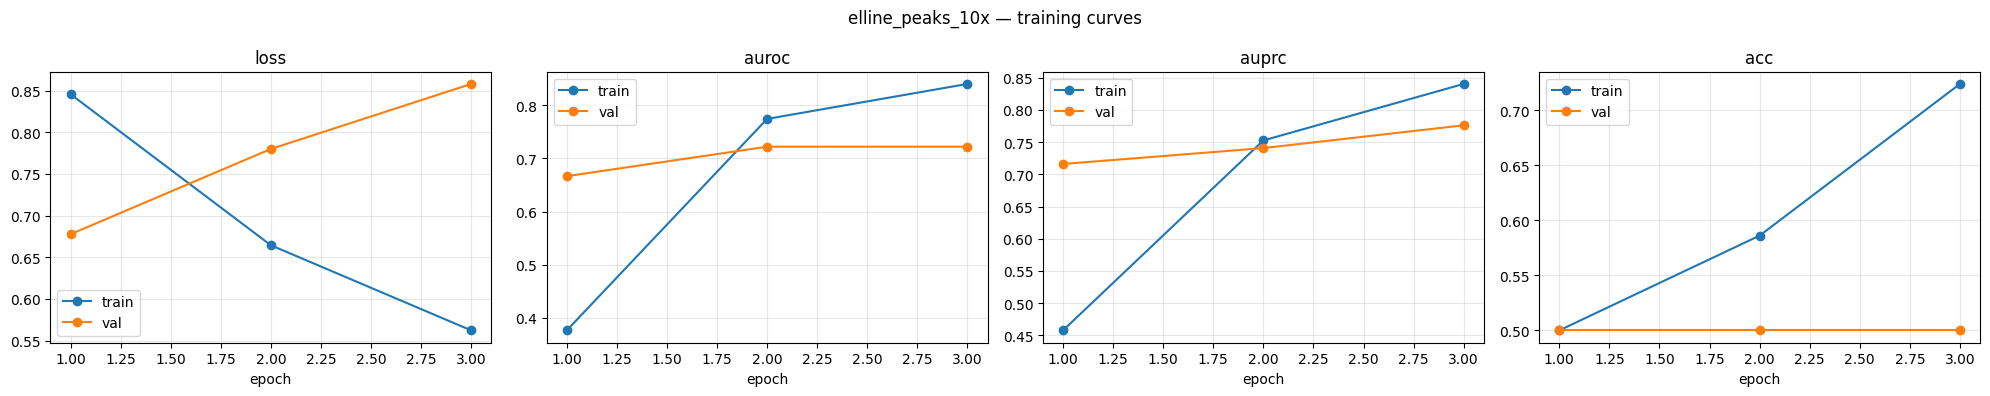

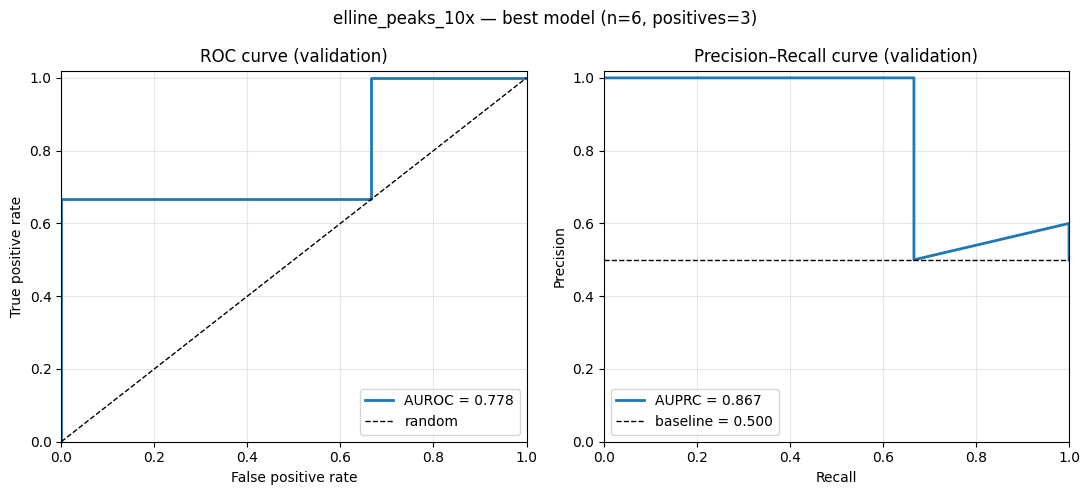

{
  "auroc": 0.7777777777777778,
  "auprc": 0.8666666666666667,
  "accuracy@0.5": 0.5,
  "n_val": 6,
  "n_val_positive": 3
}
Saved plots, predictions and metrics → outputs/elline_peaks_10x/phase_II_model/evaluation


In [11]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score,
                             average_precision_score, accuracy_score)

EVAL_MODALITIES = ["atac", "dnase", "procap", "chip_histone"]
EVAL_DIR = PHASE_II_DIR / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# ── 1. Training curves (per epoch, train vs val) ──────────────
log = pd.read_csv(PHASE_II_DIR / "training_log.csv")
metrics = [m for m in ["loss", "auroc", "auprc", "acc"] if m in log and f"val_{m}" in log]
fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4))
for ax, m in zip(np.atleast_1d(axes), metrics):
    ax.plot(log["epoch"] + 1, log[m], marker="o", label="train")
    ax.plot(log["epoch"] + 1, log[f"val_{m}"], marker="o", label="val")
    ax.set(title=m, xlabel="epoch")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle(f"{EXPERIMENT_NAME} — training curves")
fig.tight_layout()
fig.savefig(EVAL_DIR / "training_curves.png", dpi=150)
plt.show()


# ── 2. Predict the validation set with the best checkpoint ────
def predict_indices(model, indices, batch_size=BATCH_SIZE):
    """indices: list of (h5_path, group, row, y) as saved in data_split.json."""
    scores = []
    for start in range(0, len(indices), batch_size):
        X = {mod: [] for mod in EVAL_MODALITIES}
        files = {}
        try:
            for path, group, row, _ in indices[start:start + batch_size]:
                if path not in files:
                    files[path] = h5py.File(path, "r")
                for mod in EVAL_MODALITIES:
                    X[mod].append(files[path][group][mod][int(row)])
        finally:
            for f in files.values():
                f.close()
        batch = {mod: np.stack(X[mod]).astype(np.float32) for mod in EVAL_MODALITIES}
        scores.append(np.asarray(model.predict_on_batch(batch)).ravel())
    return np.concatenate(scores)


best_model = keras.models.load_model(str(PHASE_II_DIR / "best_model.keras"))
with open(PHASE_II_DIR / "data_split.json") as f:
    val_idx = json.load(f)["val"]

y_true  = np.array([entry[3] for entry in val_idx], dtype=int)
y_score = predict_indices(best_model, val_idx)

pd.DataFrame({
    "h5_path": [e[0] for e in val_idx], "group": [e[1] for e in val_idx],
    "row": [e[2] for e in val_idx], "y_true": y_true, "y_score": y_score,
}).to_csv(EVAL_DIR / "val_predictions.csv", index=False)


# ── 3. ROC and PR curves ──────────────────────────────────────
auroc = roc_auc_score(y_true, y_score)
auprc = average_precision_score(y_true, y_score)
acc   = accuracy_score(y_true, y_score >= 0.5)
fpr, tpr, _        = roc_curve(y_true, y_score)
precision, recall, _ = precision_recall_curve(y_true, y_score)
pos_rate = y_true.mean()

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 5))
ax_roc.plot(fpr, tpr, lw=2, label=f"AUROC = {auroc:.3f}")
ax_roc.plot([0, 1], [0, 1], "k--", lw=1, label="random")
ax_roc.set(title="ROC curve (validation)", xlabel="False positive rate",
           ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.02))
ax_pr.plot(recall, precision, lw=2, label=f"AUPRC = {auprc:.3f}")
ax_pr.axhline(pos_rate, color="k", ls="--", lw=1, label=f"baseline = {pos_rate:.3f}")
ax_pr.set(title="Precision–Recall curve (validation)", xlabel="Recall",
          ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
for ax in (ax_roc, ax_pr):
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right" if ax is ax_roc else "lower left")
fig.suptitle(f"{EXPERIMENT_NAME} — best model (n={len(y_true)}, positives={int(y_true.sum())})")
fig.tight_layout()
fig.savefig(EVAL_DIR / "roc_pr_curves.png", dpi=150)
plt.show()

eval_metrics = {"auroc": auroc, "auprc": auprc, "accuracy@0.5": acc,
                "n_val": int(len(y_true)), "n_val_positive": int(y_true.sum())}
with open(EVAL_DIR / "metrics.json", "w") as f:
    json.dump(eval_metrics, f, indent=2, default=float)
print(json.dumps(eval_metrics, indent=2, default=float))
print(f"Saved plots, predictions and metrics → {EVAL_DIR}")